In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from qick import *
from tqdm.notebook import tqdm
import time
import pandas as pd
from pathlib import Path
from scipy.optimize import curve_fit
import json

mpl.rcParams['figure.figsize'] = 12, 8
mpl.rcParams.update({'font.size': 12})

In [2]:
soc = QickSoc()
soccfg = soc
print(soc)

QICK running on RFSoC4x2, software version 0.2.405

Firmware configuration (built Wed Sep  6 18:49:29 2023):

	Global clocks (MHz): tProc dispatcher timing 409.600, RF reference 491.520
	Groups of related clocks: [tProc clock, DAC tile 0], [DAC tile 2], [ADC tile 0]

	2 signal generator channels:
	0:	axis_signal_gen_v6 - fs=9830.400 Msps, fabric=614.400 MHz
		envelope memory: 65536 complex samples (6.667 us)
		32-bit DDS, range=9830.400 MHz
		DAC tile 0, blk 0 is DAC_B
	1:	axis_signal_gen_v6 - fs=9830.400 Msps, fabric=614.400 MHz
		envelope memory: 65536 complex samples (6.667 us)
		32-bit DDS, range=9830.400 MHz
		DAC tile 2, blk 0 is DAC_A

	2 readout channels:
	0:	axis_readout_v2 - configured by PYNQ
		fs=4423.680 Msps, decimated=552.960 MHz, 32-bit DDS, range=4423.680 MHz
		axis_avg_buffer v1.0 (no edge counter, no weights)
		memory 16384 accumulated, 1024 decimated (1.852 us)
		triggered by output 7, pin 14, feedback to tProc input 0
		ADC tile 0, blk 0 is ADC_D
	1:	axis_readout_v

In [3]:
# =============================================================
# Two-photon transition: |g,0> -> |e,1> -> |e,0> -> measure
# Cavity drive:  f_cav_g - delta          (fixed, delta = 3 MHz)
# Qubit drive:   f_ge + delta + epsilon   (sweep epsilon to find sweet spot)
# Both drives sent simultaneously, duration = 10 us
# Readout: high power punch-out
# =============================================================

class TwoPhotonTransitionProgram(AveragerProgram):
    def initialize(self):
        cfg = self.cfg

        # ── Channel aliases ──────────────────────────────────────
        self.res_ch   = cfg["res_ch"]
        self.qubit_ch = cfg["qubit_ch"]
        self.adc_ch   = cfg["ro_ch"]

        # ── Declare generators ───────────────────────────────────
        self.declare_gen(ch=self.res_ch,   nqz=2)
        self.declare_gen(ch=self.qubit_ch, nqz=1)

        # ── Declare readout ──────────────────────────────────────
        self.declare_readout(
            ch=self.adc_ch,
            length=self.us2cycles(cfg["readout_length"], ro_ch=self.adc_ch),
            freq=cfg["f_punchout"],
            gen_ch=self.res_ch
        )

        # ── Drive frequencies ────────────────────────────────────
        # Cavity drive: dressed |g> cavity freq, detuned by -delta
        f_cav_drive   = cfg["f_cav_g"] - cfg["delta"]              # MHz
        # Qubit drive: f_ge + delta + epsilon (epsilon swept externally)
        f_qubit_drive = cfg["f_ge"] + cfg["delta"] + cfg["epsilon"] # MHz

        # ── Convert to registers ─────────────────────────────────
        self.f_cav_reg      = self.freq2reg(f_cav_drive,       gen_ch=self.res_ch)
        self.f_qubit_reg    = self.freq2reg(f_qubit_drive,     gen_ch=self.qubit_ch)
        self.f_punchout_reg = self.freq2reg(cfg["f_punchout"], gen_ch=self.res_ch,
                                            ro_ch=self.adc_ch)

        # ── Cavity drive pulse ───────────────────────────────────
        self.set_pulse_registers(
            ch=self.res_ch,
            style="const",
            freq=self.f_cav_reg,
            phase=0,
            gain=cfg["cav_gain"],
            length=self.us2cycles(cfg["drive_length"], gen_ch=self.res_ch)
        )

        # ── Qubit drive pulse ────────────────────────────────────
        self.set_pulse_registers(
            ch=self.qubit_ch,
            style="const",
            freq=self.f_qubit_reg,
            phase=0,
            gain=cfg["qubit_gain"],
            length=self.us2cycles(cfg["drive_length"], gen_ch=self.qubit_ch)
        )

        self.synci(200)

    def body(self):
        cfg = self.cfg

        # ── Step 1+2: Simultaneous two-photon drive ───────────────
        # Cavity and qubit drives fired together — no sync_all between them
        #self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
        self.set_pulse_registers(
            ch=self.res_ch,
            style="const",
            freq=self.f_cav_reg,
            phase=0,
            gain=cfg["cav_gain"],
            length=self.us2cycles(cfg["drive_length"], gen_ch=self.res_ch)
        )
        self.pulse(ch=self.res_ch)
        self.set_pulse_registers(
            ch=self.qubit_ch,
            style="const",
            freq=self.f_qubit_reg,
            phase=0,
            gain=cfg["qubit_gain"],
            length=self.us2cycles(cfg["drive_length"], gen_ch=self.qubit_ch)
        )
        self.pulse(ch=self.qubit_ch)
        self.sync_all(self.us2cycles(0.05))   # wait for both pulses to finish

        # ── Step 3: Wait for cavity photon to decay -> |e,0> ─────
        self.sync_all(self.us2cycles(cfg["wait_decay"]))

        # ── Step 4: Punch-out readout ────────────────────────────
        self.set_pulse_registers(
            ch=self.res_ch,
            style="const",
            freq=self.f_punchout_reg,
            phase=cfg["res_phase"],
            gain=cfg["res_gain"],
            length=self.us2cycles(cfg["readout_length"], gen_ch=self.res_ch)
        )

        self.measure(
            pulse_ch=self.res_ch,
            adcs=[self.adc_ch],
            adc_trig_offset=self.us2cycles(cfg["adc_trig_offset"], ro_ch=self.adc_ch),
            wait=True,
            syncdelay=self.us2cycles(cfg["relax_delay"])
        )




In [7]:
# =============================================================
# Configuration
# =============================================================
hw_cfg = {
    "res_ch":   1,
    "qubit_ch": 0,
    "ro_ch":    0,
}

base_cfg = {
    # Fixed detuning
    "delta":          10.0,      # MHz - fixed throughout sweep

    # Cavity drive (low power, dressed |g> frequency)
    "f_cav_g":        6568.0,  # MHz - from low-power spectroscopy
    "cav_gain":       3000,      # low power

    # Qubit drive
    "f_ge":           3800.4,  # MHz - calibrated dressed f_ge (1 photon in cavity)
    "qubit_gain":     20000,    # from Rabi calibration

    # Drive length (both cavity and qubit, same duration)
    "drive_length":   20.0,     # us - long enough for two-photon Rabi

    # Cavity decay wait
    "wait_decay":     0.0,      # us - ~ 3-5 / kappa

    # Readout (high power punch-out)
    "f_punchout":     6567.43,  # MHz
    "res_gain":       5300,
    "res_phase":      966971716,  # run single shot calibration to get this 
    "readout_length": 40.0,     # us
    "adc_trig_offset":0.2,      # us
    "relax_delay":    1000,     # us
    "reps":           700,
    'threshold':      -8,
}



In [10]:
# =============================================================
# Epsilon sweep (software loop)
# =============================================================
epsilon_start  = -7.0   # MHz
epsilon_stop   =  -5.0  # MHz
n_points       =  101

epsilon_list = np.linspace(epsilon_start, epsilon_stop, n_points)

i_data, q_data = [], []

# print(f"Fixed delta    = {base_cfg['delta']} MHz")
# print(f"Cavity drive   = {base_cfg['f_cav_g'] - base_cfg['delta']:.3f} MHz")
# print(f"Sweeping epsilon from {epsilon_start} to {epsilon_stop} MHz ({n_points} points)")
# print(f"Qubit drive range: {base_cfg['f_ge'] + base_cfg['delta'] + epsilon_start:.3f}"
#       f" to {base_cfg['f_ge'] + base_cfg['delta'] + epsilon_stop:.3f} MHz")
print("Sweep start >>>")

for epsilon in tqdm(epsilon_list):
    cfg = {**hw_cfg, **base_cfg, "epsilon": epsilon}

    prog = TwoPhotonTransitionProgram(soccfg, cfg)
    avgi, avgq = prog.acquire(soc, threshold=cfg["threshold"],load_pulses=True, progress=False)

    i_data.append(avgi[0][0])
    q_data.append(avgq[0][0])

i_data = np.array(i_data)
q_data = np.array(q_data)
mag    = np.sqrt(i_data**2 + q_data**2)

print("Sweep complete.")



Sweep start >>>


  0%|          | 0/101 [00:00<?, ?it/s]

Sweep complete.


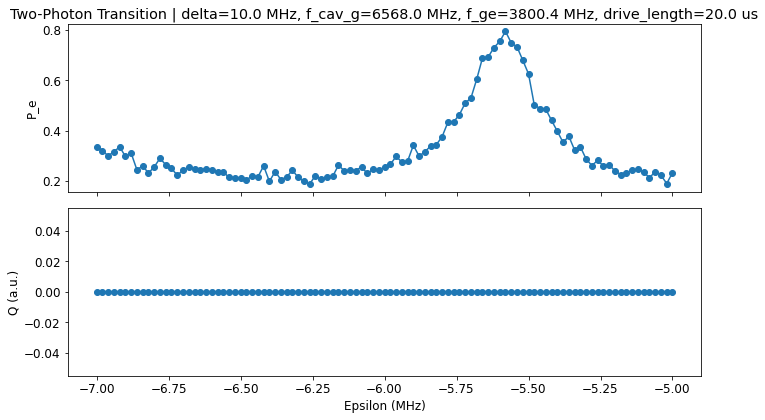

In [11]:
# =============================================================
# Plot
# =============================================================
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axs[0].plot(epsilon_list, i_data, 'o-')
axs[0].set_ylabel("P_e")
axs[0].set_title(
    f"Two-Photon Transition | delta={base_cfg['delta']} MHz, "
    f"f_cav_g={base_cfg['f_cav_g']} MHz, f_ge={base_cfg['f_ge']} MHz, "
    f"drive_length={base_cfg['drive_length']} us"
)

axs[1].plot(epsilon_list, q_data, 'o-')
axs[1].set_ylabel("Q (a.u.)")
axs[1].set_xlabel("Epsilon (MHz)")

plt.tight_layout()
plt.show()

═════════════════════════════════════════════
  Lorentzian Fit Results
═════════════════════════════════════════════
  Resonance  ε₀    = -5.5896 ± 0.0034  MHz
  Linewidth  Γ     = 0.2451 ± 0.0115  MHz
  Amplitude  A     = 0.5642 ± 0.0157
  Background P_bg  = 0.2252 ± 0.0049
  Peak P_e         = 0.7895
═════════════════════════════════════════════


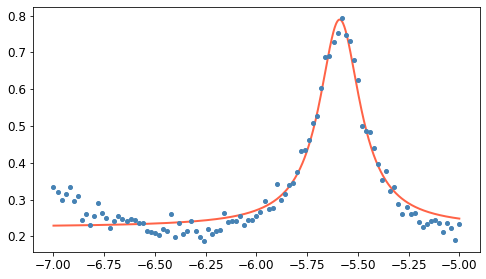

In [15]:
# ── Fit model: Lorentzian on a flat background ────────────────────────────────
def lorentzian(eps, eps0, gamma, A, P_bg):
    """
    eps0  : resonance detuning (MHz) — what we extract
    gamma : FWHM linewidth (MHz)
    A     : peak amplitude above background
    P_bg  : background population
    """
    return P_bg + A * (gamma / 2)**2 / ((eps - eps0)**2 + (gamma / 2)**2)

# ── Initial guesses from the plot ─────────────────────────────────────────────
Pe = i_data
eps = epsilon_list
idx_peak = np.argmax(Pe)
eps0_guess  = eps[idx_peak]          # ~-5.6 MHz from plot
gamma_guess = 0.3                    # rough FWHM estimate (MHz)
A_guess     = Pe[idx_peak] - np.percentile(Pe, 10)
Pbg_guess   = np.percentile(Pe, 10)

p0 = [eps0_guess, gamma_guess, A_guess, Pbg_guess]

# Optional bounds to keep parameters physical
bounds = (
    [eps.min(), 0,    0,    0  ],   # lower
    [eps.max(), 5.0,  1.0,  1.0],   # upper
)

popt, pcov = curve_fit(lorentzian, eps, Pe, p0=p0, bounds=bounds, maxfev=10000)
perr = np.sqrt(np.diag(pcov))

eps0_fit, gamma_fit, A_fit, Pbg_fit = popt

print("═" * 45)
print("  Lorentzian Fit Results")
print("═" * 45)
print(f"  Resonance  ε₀    = {eps0_fit:.4f} ± {perr[0]:.4f}  MHz")
print(f"  Linewidth  Γ     = {gamma_fit:.4f} ± {perr[1]:.4f}  MHz")
print(f"  Amplitude  A     = {A_fit:.4f} ± {perr[2]:.4f}")
print(f"  Background P_bg  = {Pbg_fit:.4f} ± {perr[3]:.4f}")
print(f"  Peak P_e         = {A_fit + Pbg_fit:.4f}")
print("═" * 45)

# ── Plot ──────────────────────────────────────────────────────────────────────
eps_fine = np.linspace(eps.min(), eps.max(), 1000)
Pe_fit   = lorentzian(eps_fine, *popt)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(eps, Pe, "o", ms=4, color="steelblue", label="Data", zorder=5)
ax.plot(eps_fine, Pe_fit, color="tomato", lw=2,
        label=rf"Lorentzian fit"
              f"\n$\varepsilon_0 = {eps0_fit:.4f} \pm {perr[0]:.4f}$ MHz"
              f"\n$\Gamma = {gamma_fit:.4f} \pm {perr[1]:.4f}$ MHz")

# # Mark the extracted peak position
# ax.axvline(eps0_fit, color="tomato", lw=1, ls="--", alpha=0.6)
# ax.axhline(Pbg_fit,  color="gray",   lw=1, ls=":",  alpha=0.6, label="Background")

# # # HWHM markers
# # ax.annotate("", xy=(eps0_fit + gamma_fit/2, Pbg_fit + A_fit/2),
# #             xytext=(eps0_fit - gamma_fit/2, Pbg_fit + A_fit/2),
# #             arrowprops=dict(arrowstyle="<->", color="purple"))
# # ax.text(eps0_fit, Pbg_fit + A_fit/2 + 0.01,
# #         rf"$\Gamma={gamma_fit:.3f}$ MHz", ha="center", color="purple", fontsize=9)

# ax.set_xlabel("Epsilon (MHz)", fontsize=12)
# ax.set_ylabel(r"$P_e$", fontsize=12)
# ax.set_title(f"Two-Photon Spectroscopy — Resonance at ε₀ = {eps0_fit:.4f} MHz",
#              fontsize=12)
# ax.legend(fontsize=9, loc="upper left")
# ax.grid(True, ls="--", alpha=0.35)

# #plt.tight_layout()
# plt.savefig("spectroscopy_fit.png", dpi=150)
plt.show()

In [7]:
sdate = '26_10_09'                             # Date the data is saved 
save_dir= Path(f"Lab_Data/{sdate}")
save_dir.mkdir(parents = True, exist_ok=True)



In [ ]:
filename_iq = f"2Photon_transition_spectrum.csv"
filepath_iq = save_dir/filename_iq

df = pd.DataFrame(i_data, index=epsilon_list)
df.to_csv(filepath_iq, index = True)

# Varying drive length, check P_e saturation

In [26]:
# =============================================================
# Configuration — parked at two-photon resonance
# =============================================================
hw_cfg = {
    "res_ch":   1,
    "qubit_ch": 0,
    "ro_ch":    0,
}


base_cfg = {
    # Fixed detuning
    "delta":          10.0,      # MHz - fixed throughout sweep
    "epsilon":        -5.59,    # MHz - parked at two-photon resonance peak

    # Cavity drive (low power, dressed |g> frequency)
    "f_cav_g":        6568.0,  # MHz - from low-power spectroscopy
    "cav_gain":       3000,      # low power

    # Qubit drive
    "f_ge":           3800.4,  # MHz - calibrated dressed f_ge (1 photon in cavity)
    "qubit_gain":     20000,    # from Rabi calibration

    # Drive length (both cavity and qubit, same duration)
    #"drive_length":   20.0,     # us - long enough for two-photon Rabi

    # Cavity decay wait
    "wait_decay":     0.0,      # us - ~ 3-5 / kappa


}

readout_cfg ={
        # Readout (high power punch-out)
    "f_punchout":     6567.43,  # MHz
    "res_gain":       5300,
    "res_phase":      954770595,  # run single shot calibration to get this 
    "readout_length": 40.0,     # us
    "adc_trig_offset":0.2,      # us
    "relax_delay":    1000,     # us
    "reps":           1000,
    'threshold':      -8,
}

# =============================================================
# Drive length sweep
# =============================================================
drive_length_start = 0.1    # us
drive_length_stop  = 50.0  # us - long enough to see saturation
n_points           = 51

drive_length_list = np.linspace(drive_length_start, drive_length_stop, n_points)

i_data, q_data = [], []

print(f"delta          = {base_cfg['delta']} MHz")
print(f"epsilon        = {base_cfg['epsilon']} MHz")
print(f"Cavity drive   = {base_cfg['f_cav_g'] - base_cfg['delta']:.3f} MHz")
print(f"Qubit drive    = {base_cfg['f_ge'] + base_cfg['delta'] + base_cfg['epsilon']:.3f} MHz")
print(f"Sweeping drive_length from {drive_length_start} to {drive_length_stop} us ({n_points} points)")
print()



delta          = 10.0 MHz
epsilon        = -5.59 MHz
Cavity drive   = 6558.000 MHz
Qubit drive    = 3804.810 MHz
Sweeping drive_length from 0.1 to 50.0 us (51 points)



In [17]:
for drive_length in tqdm(drive_length_list):
    cfg = {**hw_cfg, **base_cfg, **readout_cfg, "drive_length": drive_length}

    prog = TwoPhotonTransitionProgram(soccfg, cfg)
    avgi, avgq = prog.acquire(soc, threshold=cfg["threshold"], load_pulses=True, progress=False)

    i_data.append(avgi[0][0])
    q_data.append(avgq[0][0])

i_data = np.array(i_data)
q_data = np.array(q_data)
mag    = np.sqrt(i_data**2 + q_data**2)

print("Sweep complete.")

# =============================================================


  0%|          | 0/51 [00:00<?, ?it/s]

Sweep complete.


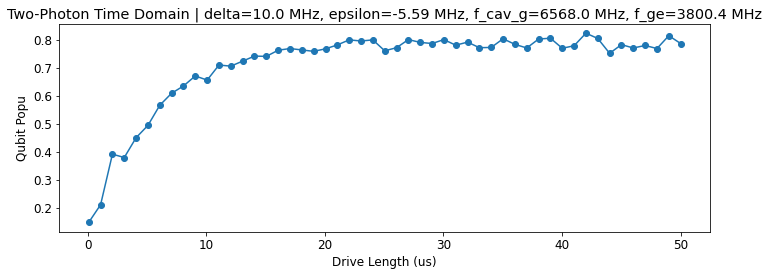

In [18]:
# Plot — with reference lines for |g> and |e> mean I values
# =============================================================
i_g_mean = -15.0   # update from your single-shot calibration
i_e_mean = -2.0    # update from your single-shot calibration

fig, axs = plt.subplots(1, 1, figsize=(10, 4), sharex=True)

axs.plot(drive_length_list, i_data, 'o-')

axs.set_ylabel("Qubit Popu")
#axs.legend()
axs.set_title(
    f"Two-Photon Time Domain | delta={base_cfg['delta']} MHz, "
    f"epsilon={base_cfg['epsilon']} MHz, "
    f"f_cav_g={base_cfg['f_cav_g']} MHz, f_ge={base_cfg['f_ge']} MHz")


# axs[2].plot(drive_length_list, mag, 'o-', color='green')
# axs[2].set_ylabel("Magnitude (a.u.)")
axs.set_xlabel("Drive Length (us)")

plt.tight_layout()
plt.show()

In [19]:
sdate = '26_10_12'                             # Date the data is saved 
save_dir= Path(f"Lab_Data/{sdate}")
save_dir.mkdir(parents = True, exist_ok=True)

In [20]:
filename_iq = f"2Photon_Pumping_00.csv"
filepath_iq = save_dir/filename_iq
#df = pd.DataFrame(Time_IQ, index = Time_step)
df = pd.DataFrame(i_data, index=drive_length_list)
# df.index.name = "Drive_freq"
# df.columns.name = "Time (ns)"
df.to_csv(filepath_iq, index = True)

Fitting the decay curve

In [21]:
def population_model(t, I_ss, I_0, Gamma_eff):
    return I_ss + (I_0 - I_ss) * np.exp(-Gamma_eff * t)

# ── Initial guesses from the plot ────────────────────────────
I_0_guess        = 0.05   # starting I value (near |g> mean)
I_ss_guess       = 0.8   # steady state I value from plot
Gamma_eff_guess  = 0.3     # 1/us - rough guess from plot (rises in ~5-10 us)

p0 = [I_ss_guess, I_0_guess, Gamma_eff_guess]

# ── Bounds to keep parameters physical ──────────────────────
# I_ss between |g> and |e>, Gamma_eff > 0
# bounds = (
#     [-10,  -20,  0.0],   # lower bounds: [I_ss, I_0, Gamma_eff]
#     [ 0,    0,   10.0],  # upper bounds
# )

# ── Fit ──────────────────────────────────────────────────────
popt, pcov = curve_fit(population_model, drive_length_list, i_data,
                       p0=p0)
perr = np.sqrt(np.diag(pcov))

I_ss_fit, I_0_fit, Gamma_eff_fit = popt
I_ss_err, I_0_err, Gamma_eff_err = perr

# ── Convert to physical quantities ───────────────────────────
T_eff       = 1.0 / Gamma_eff_fit          # us
T_eff_err   = Gamma_eff_err / Gamma_eff_fit**2

# Steady state population from IQ reference values
# P_e_ss = (I_ss - I_g) / (I_e - I_g)
P_e_ss     = (I_ss_fit - i_g_mean) / (i_e_mean - i_g_mean)
P_e_ss_err = I_ss_err / abs(i_e_mean - i_g_mean)

print("=" * 50)
print("Fit Results:")
print(f"  I_0       = {I_0_fit:.3f} ± {I_0_err:.3f}  (initial, |g> mean = {i_g_mean})")
print(f"  I_ss      = {I_ss_fit:.3f} ± {I_ss_err:.3f}  (steady state, |e> mean = {i_e_mean})")
print(f"  Gamma_eff = {Gamma_eff_fit:.4f} ± {Gamma_eff_err:.4f} MHz")
print(f"  T_eff     = {T_eff:.2f} ± {T_eff_err:.2f} us")
print(f"  P_e (ss)  = {P_e_ss:.3f} ± {P_e_ss_err:.3f}")
print("=" * 50)



Fit Results:
  I_0       = 0.124 ± 0.014  (initial, |g> mean = -15.0)
  I_ss      = 0.790 ± 0.004  (steady state, |e> mean = -2.0)
  Gamma_eff = 0.1767 ± 0.0065 MHz
  T_eff     = 5.66 ± 0.21 us
  P_e (ss)  = 1.215 ± 0.000


  Gamma_1   = 0.0132 MHz  (1/T1, T1 = 76.0 us)
  Gamma_pump= 0.1635 ± 0.0065 MHz
  T_pump    = 6.11 us  (two-photon pump timescale)


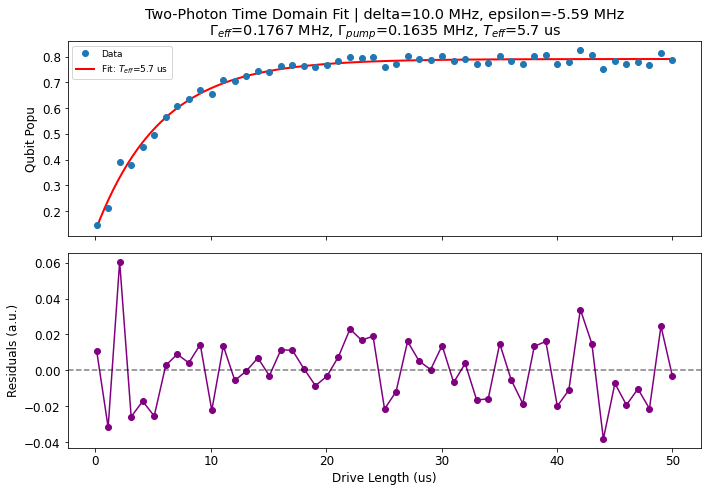

In [22]:
# ── From Gamma_eff, extract pump rate ────────────────────────
# Gamma_eff = Gamma_pump + Gamma_1
# Gamma_1 = 1/T1 (known from T1 measurement)
T1          = 76.0   # us - from your T1 measurement
Gamma_1     = 1.0 / T1
Gamma_pump  = Gamma_eff_fit - Gamma_1
T_pump      = 1.0 / Gamma_pump if Gamma_pump > 0 else np.inf

print(f"  Gamma_1   = {Gamma_1:.4f} MHz  (1/T1, T1 = {T1} us)")
print(f"  Gamma_pump= {Gamma_pump:.4f} ± {Gamma_eff_err:.4f} MHz")
print(f"  T_pump    = {T_pump:.2f} us  (two-photon pump timescale)")
print("=" * 50)

# ── Plot with fit ─────────────────────────────────────────────
t_fine = np.linspace(drive_length_list[0], drive_length_list[-1], 500)
I_fit  = population_model(t_fine, *popt)

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axs[0].plot(drive_length_list, i_data, 'o', label='Data', zorder=3)
axs[0].plot(t_fine, I_fit, '-', color='red', linewidth=2,
            label=f'Fit: $T_{{eff}}$={T_eff:.1f} us')
# axs[0].axhline(i_g_mean, color='blue',  linestyle='--', alpha=0.5, label='|g> mean')
# axs[0].axhline(i_e_mean, color='red',   linestyle='--', alpha=0.5, label='|e> mean')
# axs[0].axhline(I_ss_fit, color='green', linestyle=':', alpha=0.8,
#                label=f'$I_{{ss}}$ = {I_ss_fit:.2f}')
axs[0].set_ylabel("Qubit Popu")
axs[0].legend(fontsize=9)
axs[0].set_title(
    f"Two-Photon Time Domain Fit | delta={base_cfg['delta']} MHz, "
    f"epsilon={base_cfg['epsilon']} MHz\n"
    f"$\\Gamma_{{eff}}$={Gamma_eff_fit:.4f} MHz, "
    f"$\\Gamma_{{pump}}$={Gamma_pump:.4f} MHz, "
    f"$T_{{eff}}$={T_eff:.1f} us"
)

# Residuals
residuals = i_data - population_model(drive_length_list, *popt)
axs[1].plot(drive_length_list, residuals, 'o-', color='purple')
axs[1].axhline(0, color='k', linestyle='--', alpha=0.5)
axs[1].set_ylabel("Residuals (a.u.)")
axs[1].set_xlabel("Drive Length (us)")

plt.tight_layout()
plt.show()

# Dissipator

In [23]:
# =============================================================
# Dissipator: |e,0> -> |g,0>
# Sequence:
#   1. Pi-pulse on qubit -> prepare |e,0>
#   2. Simultaneous two-photon drive -> |g,1>
#      Cavity drive:  f_cav_e - delta
#      Qubit drive:   f_ge_1ph + delta + epsilon
#   3. Wait for cavity decay -> |g,0>
#   4. Punch-out readout
# =============================================================

class DissipatorProgram(AveragerProgram):
    def initialize(self):
        cfg = self.cfg

        # ── Channel aliases ──────────────────────────────────────
        self.res_ch   = cfg["res_ch"]
        self.qubit_ch = cfg["qubit_ch"]
        self.adc_ch   = cfg["ro_ch"]

        # ── Declare generators ───────────────────────────────────
        self.declare_gen(ch=self.res_ch,   nqz=2)
        self.declare_gen(ch=self.qubit_ch, nqz=1)

        # ── Declare readout ──────────────────────────────────────
        self.declare_readout(
            ch=self.adc_ch,
            length=self.us2cycles(cfg["readout_length"], ro_ch=self.adc_ch),
            freq=cfg["f_punchout"],
            gen_ch=self.res_ch
        )

        # ── Frequency calculations ───────────────────────────────
        # Pi-pulse: resonant at bare f_ge (no detuning, no photon in cavity)
        f_pi         = cfg["f_ge"]

        # Two-photon drive for dissipation direction:
        # Cavity drive: f_cav_e - delta
        # Qubit drive:  f_ge_1ph + delta + epsilon
        f_cav_drive   = cfg["f_cav_e"]   - cfg["delta"]
        f_qubit_drive = cfg["f_ge_1ph"]  + cfg["delta"] + cfg["epsilon"]

        # ── Convert to registers ─────────────────────────────────
        self.f_pi_reg       = self.freq2reg(f_pi,           gen_ch=self.qubit_ch)
        self.f_cav_reg      = self.freq2reg(f_cav_drive,    gen_ch=self.res_ch)
        self.f_qubit_reg    = self.freq2reg(f_qubit_drive,  gen_ch=self.qubit_ch)
        self.f_punchout_reg = self.freq2reg(cfg["f_punchout"], gen_ch=self.res_ch,
                                            ro_ch=self.adc_ch)

        self.synci(200)

    def body(self):
        cfg = self.cfg

        # ── Step 1: Pi-pulse -> prepare |e,0> ────────────────────
        self.set_pulse_registers(
            ch=self.qubit_ch,
            style="const",
            freq=self.f_pi_reg,
            phase=0,
            gain=cfg["pi_gain"],
            length=self.us2cycles(cfg["pi_length"], gen_ch=self.qubit_ch)
        )
        self.pulse(ch=self.qubit_ch)
        self.sync_all(self.us2cycles(0.05))   # wait for pi-pulse to finish

        # ── Step 2: Simultaneous two-photon drive ─────────────────
        # Cavity drive: f_cav_e - delta
        self.set_pulse_registers(
            ch=self.res_ch,
            style="const",
            freq=self.f_cav_reg,
            phase=0,
            gain=cfg["cav_gain"],
            length=self.us2cycles(cfg["drive_length"], gen_ch=self.res_ch)
        )
        self.pulse(ch=self.res_ch)

        # Qubit drive: f_ge_1ph + delta + epsilon
        # Phase = 180 deg for de-excitation direction (sigma- a†)
        self.set_pulse_registers(
            ch=self.qubit_ch,
            style="const",
            freq=self.f_qubit_reg,
            phase=self.deg2reg(180, gen_ch=self.qubit_ch),
            gain=cfg["qubit_gain"],
            length=self.us2cycles(cfg["drive_length"], gen_ch=self.qubit_ch)
        )
        self.pulse(ch=self.qubit_ch)
        self.sync_all(self.us2cycles(0.05))

        # ── Step 3: Wait for cavity decay -> |g,0> ───────────────
        self.sync_all(self.us2cycles(cfg["wait_decay"]))

        # ── Step 4: Punch-out readout ─────────────────────────────
        self.set_pulse_registers(
            ch=self.res_ch,
            style="const",
            freq=self.f_punchout_reg,
            phase=cfg["res_phase"],
            gain=cfg["res_gain"],
            length=self.us2cycles(cfg["readout_length"], gen_ch=self.res_ch)
        )

        self.measure(
            pulse_ch=self.res_ch,
            adcs=[self.adc_ch],
            adc_trig_offset=self.us2cycles(cfg["adc_trig_offset"], ro_ch=self.adc_ch),
            wait=True,
            syncdelay=self.us2cycles(cfg["relax_delay"])
        )




In [27]:
# =============================================================
# Configuration
# =============================================================
hw_cfg = {
    "res_ch":   1,
    "qubit_ch": 0,
    "ro_ch":    0,
}

expt_cfg = {
    # Fixed detuning
    "delta":          10.0,     # MHz - same as pumping direction
#    "epsilon":        0.0,      # MHz - sweep this to find resonance

    # Pi-pulse (prepare |e,0>)
    "f_ge":           3800.4,   # MHz - bare qubit frequency (no photon)
    "pi_gain":        20000,    # from Rabi calibration
    "pi_length":      0.115,    # us - calibrated pi-pulse length

    # Cavity drive (conditioned on qubit in |e>)
    "f_cav_e":        6567.0,   # MHz - dressed cavity freq when qubit in |e>
                                #       calibrate from two-tone spectroscopy
    "cav_gain":       3000,

    # Qubit drive (conditioned on 1 photon in cavity)
    "f_ge_1ph":       3800.4,   # MHz - dressed qubit freq with 1 photon
                                #       calibrate from two-tone spectroscopy
    "qubit_gain":     20000,

    # Two-photon drive length
    "drive_length":   10.0,     # us

    # Cavity decay wait
    "wait_decay":     0.0,      # us - kappa is fast enough
}

config = {**hw_cfg, **expt_cfg, **readout_cfg}

# =============================================================
# Epsilon sweep to find two-photon resonance
# =============================================================
epsilon_start = -17.0    # MHz
epsilon_stop  =  -13.0    # MHz
n_points      =  101

epsilon_list = np.linspace(epsilon_start, epsilon_stop, n_points)

i_data_diss, q_data_diss = [], []

print(f"Dissipator sweep")
print(f"Pi-pulse:    f_ge    = {expt_cfg['f_ge']} MHz")
print(f"Cavity drive: f_cav_e - delta = {expt_cfg['f_cav_e'] - expt_cfg['delta']:.3f} MHz")
print(f"Qubit drive:  f_ge_1ph + delta + epsilon")
print(f"Sweeping epsilon from {epsilon_start} to {epsilon_stop} MHz ({n_points} points)")
print()

for epsilon in tqdm(epsilon_list):
    cfg = {**hw_cfg, **expt_cfg,**readout_cfg, "epsilon": epsilon}

    prog = DissipatorProgram(soccfg, cfg)
    avgi, avgq = prog.acquire(soc,threshold=cfg["threshold"], load_pulses=True, progress=False)

    i_data_diss.append(avgi[0][0])
    q_data_diss.append(avgq[0][0])

i_data_diss = np.array(i_data_diss)
q_data_diss = np.array(q_data_diss)
mag_diss    = np.sqrt(i_data_diss**2 + q_data_diss**2)

print("Sweep complete.")

# =============================================================
# Plot
# =============================================================
i_g_mean = -15.0   # from single-shot calibration
i_e_mean = -2.0    # from single-shot calibration

Dissipator sweep
Pi-pulse:    f_ge    = 3800.4 MHz
Cavity drive: f_cav_e - delta = 6557.000 MHz
Qubit drive:  f_ge_1ph + delta + epsilon
Sweeping epsilon from -17.0 to -13.0 MHz (101 points)



  0%|          | 0/101 [00:00<?, ?it/s]

Sweep complete.


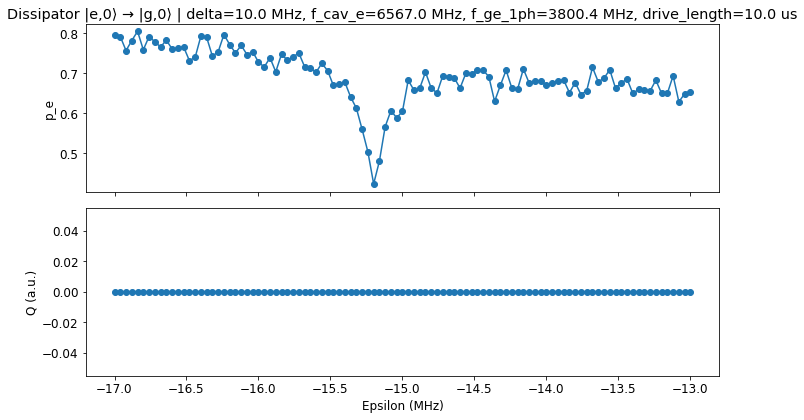

In [29]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axs[0].plot(epsilon_list, i_data_diss, 'o-')
# axs[0].axhline(i_g_mean, color='blue', linestyle='--', alpha=0.5, label='|g⟩ mean')
# axs[0].axhline(i_e_mean, color='red',  linestyle='--', alpha=0.5, label='|e⟩ mean')
axs[0].set_ylabel("p_e")
# axs[0].legend()
axs[0].set_title(
    f"Dissipator |e,0⟩ → |g,0⟩ | "
    f"delta={expt_cfg['delta']} MHz, "
    f"f_cav_e={expt_cfg['f_cav_e']} MHz, "
    f"f_ge_1ph={expt_cfg['f_ge_1ph']} MHz, "
    f"drive_length={expt_cfg['drive_length']} us"
)

axs[1].plot(epsilon_list, q_data_diss, 'o-')
axs[1].set_ylabel("Q (a.u.)")
axs[1].set_xlabel("Epsilon (MHz)")

plt.tight_layout()
plt.show()

In [43]:
expt_cfg = {
    # Parked detunings
    "delta":          10.0,     # MHz
    "epsilon":        -15.20,    # MHz - parked at dissipation resonance

    # Pi-pulse (prepare |e,0>)
    "f_ge":           3800.4,   # MHz
    "pi_gain":        20000,
    "pi_length":      0.115,    # us

    # Two-photon drive
    "f_cav_e":        6567.0,   # MHz
    "cav_gain":       0, #3000,
    "f_ge_1ph":       3800.4,   # MHz
    "qubit_gain":     20000,

    # Cavity decay wait
    "wait_decay":     0.0,      # us

}

# =============================================================
# Drive length sweep
# =============================================================
drive_length_start = 0.1    # us
drive_length_stop  = 80.0   # us
n_points           = 81

drive_length_list = np.linspace(drive_length_start, drive_length_stop, n_points)

i_data_diss, q_data_diss = [], []

print(f"Dissipator time domain sweep")
print(f"Pi-pulse:     f_ge    = {expt_cfg['f_ge']} MHz")
print(f"Cavity drive: f_cav_e - delta = {expt_cfg['f_cav_e'] - expt_cfg['delta']:.3f} MHz")
print(f"Qubit drive:  f_ge_1ph + delta + epsilon = {expt_cfg['f_ge_1ph'] + expt_cfg['delta'] + expt_cfg['epsilon']:.3f} MHz")
print(f"Sweeping drive_length from {drive_length_start} to {drive_length_stop} us ({n_points} points)")
print()



Dissipator time domain sweep
Pi-pulse:     f_ge    = 3800.4 MHz
Cavity drive: f_cav_e - delta = 6557.000 MHz
Qubit drive:  f_ge_1ph + delta + epsilon = 3795.200 MHz
Sweeping drive_length from 0.1 to 80.0 us (81 points)



In [44]:
for drive_length in tqdm(drive_length_list):
    cfg = {**hw_cfg, **expt_cfg,**readout_cfg, "drive_length": drive_length}

    prog = DissipatorProgram(soccfg, cfg)
    avgi, avgq = prog.acquire(soc, threshold=cfg["threshold"], load_pulses=True, progress=False)

    i_data_diss.append(avgi[0][0])
    q_data_diss.append(avgq[0][0])

i_data_diss = np.array(i_data_diss)
q_data_diss = np.array(q_data_diss)
mag_diss    = np.sqrt(i_data_diss**2 + q_data_diss**2)

print("Sweep complete.")

  0%|          | 0/81 [00:00<?, ?it/s]

Sweep complete.


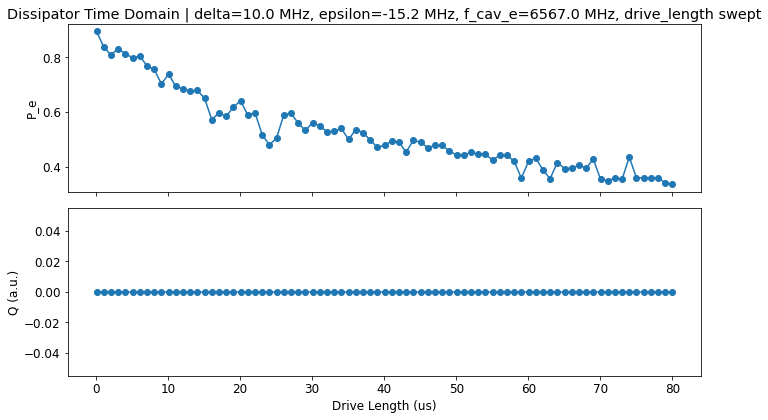

In [45]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axs[0].plot(drive_length_list, i_data_diss, 'o-')
# axs[0].axhline(i_g_mean, color='blue', linestyle='--', alpha=0.5, label='|g⟩ mean')
# axs[0].axhline(i_e_mean, color='red',  linestyle='--', alpha=0.5, label='|e⟩ mean')
axs[0].set_ylabel("P_e")
#axs[0].legend()
axs[0].set_title(
    f"Dissipator Time Domain | "
    f"delta={expt_cfg['delta']} MHz, "
    f"epsilon={expt_cfg['epsilon']} MHz, "
    f"f_cav_e={expt_cfg['f_cav_e']} MHz, "
    f"drive_length swept"
)

axs[1].plot(drive_length_list, q_data_diss, 'o-')
axs[1].set_ylabel("Q (a.u.)")
axs[1].set_xlabel("Drive Length (us)")

plt.tight_layout()
plt.show()

In [33]:
filename_iq = f"2Photon_Decaying_00.csv"
filepath_iq = save_dir/filename_iq
#df = pd.DataFrame(Time_IQ, index = Time_step)
df = pd.DataFrame(i_data_diss, index=drive_length_list)
# df.index.name = "Drive_freq"
# df.columns.name = "Time (ns)"
df.to_csv(filepath_iq, index = True)

Dissipator Fit Results:
  I_0          = 0.8600 ± 0.0123
  I_ss         = 0.3262 ± 0.0164
  Gamma_eff    = 0.0310 ± 0.0026 (1/us)
  T_eff        = 32.28 ± 2.75 us
-------------------------------------------------------
  Gamma_1      = 0.0132 (1/us)  [1/T1, T1=76.0 us]
  Gamma_diss   (from rate)  = 0.0178 ± 0.0026 (1/us)
  Gamma_diss   (from ss)    = inf (1/us)
  P_e_ss       = 0.000

Self-consistency check:
  Gamma_diss from rate = 0.0178 (1/us)
  Gamma_diss from ss   = inf (1/us)
  ✗ Inconsistent — model may need revision


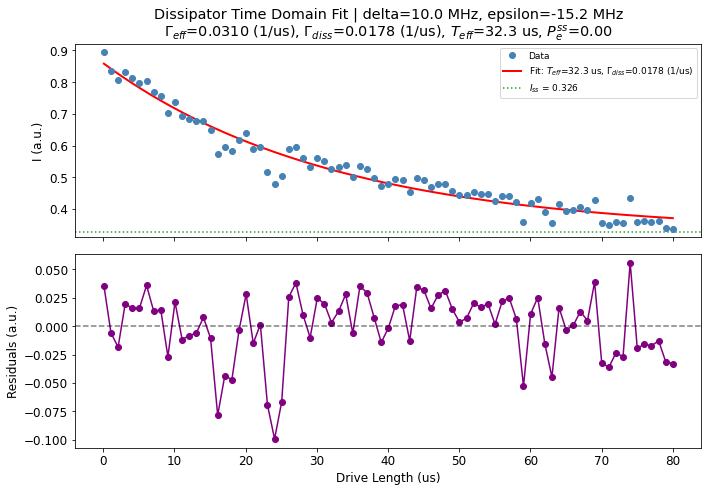

In [46]:

# =============================================================
# Curve fitting for dissipator time domain data
# Model: I(t) = I_ss + (I_0 - I_ss) * exp(-Gamma_eff * t)
# I_0      = initial value (near |e> after pi-pulse)
# I_ss     = steady state value
# Gamma_eff = Gamma_diss + Gamma_back (effective decay rate)
# =============================================================

def dissipation_model(t, I_ss, I_0, Gamma_eff):
    return I_ss + (I_0 - I_ss) * np.exp(-Gamma_eff * t)

# ── Initial guesses from the plot ────────────────────────────
I_0_guess       = 0.9    # starting value from plot
I_ss_guess      = 0.35   # steady state from plot
Gamma_eff_guess = 0.1    # 1/us - rough guess from ~10 us rise time

p0 = [I_ss_guess, I_0_guess, Gamma_eff_guess]

# ── Bounds ───────────────────────────────────────────────────
bounds = (
    [0.0,  0.5,  0.0],    # lower: [I_ss, I_0, Gamma_eff]
    [0.8,  1.2,  10.0],   # upper
)

# ── Fit ──────────────────────────────────────────────────────
popt, pcov = curve_fit(dissipation_model, drive_length_list, i_data_diss,
                       p0=p0, bounds=bounds)
perr = np.sqrt(np.diag(pcov))

I_ss_fit, I_0_fit, Gamma_eff_fit = popt
I_ss_err, I_0_err, Gamma_eff_err = perr

# ── Convert to physical quantities ───────────────────────────
T_eff     = 1.0 / Gamma_eff_fit
T_eff_err = Gamma_eff_err / Gamma_eff_fit**2

# ── Extract Gamma_diss from Gamma_eff ────────────────────────
# By analogy with pumping direction:
# Gamma_eff = Gamma_diss + Gamma_1
# where Gamma_1 = 1/T1 is the natural qubit decay
T1       = 76.0
Gamma_1  = 1.0 / T1
Gamma_diss     = Gamma_eff_fit - Gamma_1
Gamma_diss_err = Gamma_eff_err

# Steady state population
# P_e_ss = (I_ss - I_g) / (I_e - I_g)
# Note: using your actual IQ calibration values
i_g_mean = -15.0   # update from single-shot calibration
i_e_mean = -2.0    # update from single-shot calibration

# For this experiment the IQ values are normalized differently
# (punch-out gives different scale) -- use the plot values directly
I_g_ref  = i_data_diss[-5:].mean()   # steady state ~ last few points
I_e_ref  = i_data_diss[0]            # initial value ~ first point
P_e_ss   = (I_ss_fit - I_g_ref) / (I_e_ref - I_g_ref)
P_e_ss   = max(0.0, min(1.0, P_e_ss))  # clip to [0,1]

# ── From steady state: independent estimate of Gamma_diss ────
# P_e_ss = Gamma_1 / (Gamma_diss + Gamma_1)
# -> Gamma_diss = Gamma_1 * (1 - P_e_ss) / P_e_ss
if P_e_ss > 0:
    Gamma_diss_from_ss = Gamma_1 * (1 - P_e_ss) / P_e_ss
else:
    Gamma_diss_from_ss = np.inf

print("=" * 55)
print("Dissipator Fit Results:")
print(f"  I_0          = {I_0_fit:.4f} ± {I_0_err:.4f}")
print(f"  I_ss         = {I_ss_fit:.4f} ± {I_ss_err:.4f}")
print(f"  Gamma_eff    = {Gamma_eff_fit:.4f} ± {Gamma_eff_err:.4f} (1/us)")
print(f"  T_eff        = {T_eff:.2f} ± {T_eff_err:.2f} us")
print("-" * 55)
print(f"  Gamma_1      = {Gamma_1:.4f} (1/us)  [1/T1, T1={T1} us]")
print(f"  Gamma_diss   (from rate)  = {Gamma_diss:.4f} ± {Gamma_diss_err:.4f} (1/us)")
print(f"  Gamma_diss   (from ss)    = {Gamma_diss_from_ss:.4f} (1/us)")
print(f"  P_e_ss       = {P_e_ss:.3f}")
print("=" * 55)

# Self-consistency check
print(f"\nSelf-consistency check:")
print(f"  Gamma_diss from rate = {Gamma_diss:.4f} (1/us)")
print(f"  Gamma_diss from ss   = {Gamma_diss_from_ss:.4f} (1/us)")
if abs(Gamma_diss - Gamma_diss_from_ss) / Gamma_diss < 0.2:
    print("  ✓ Consistent within 20% — incoherent dissipation model valid")
else:
    print("  ✗ Inconsistent — model may need revision")

# ── Plot ──────────────────────────────────────────────────────
t_fine  = np.linspace(drive_length_list[0], drive_length_list[-1], 500)
I_fit   = dissipation_model(t_fine, *popt)

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axs[0].plot(drive_length_list, i_data_diss, 'o',
            color='steelblue', label='Data', zorder=3)
axs[0].plot(t_fine, I_fit, '-', color='red', linewidth=2,
            label=f'Fit: $T_{{eff}}$={T_eff:.1f} us, '
                  f'$\\Gamma_{{diss}}$={Gamma_diss:.4f} (1/us)')
axs[0].axhline(I_ss_fit, color='green', linestyle=':',
               alpha=0.8, label=f'$I_{{ss}}$ = {I_ss_fit:.3f}')
axs[0].set_ylabel("I (a.u.)")
axs[0].legend(fontsize=9)
axs[0].set_title(
    f"Dissipator Time Domain Fit | "
    f"delta={expt_cfg['delta']} MHz, "
    f"epsilon={expt_cfg['epsilon']} MHz\n"
    f"$\\Gamma_{{eff}}$={Gamma_eff_fit:.4f} (1/us), "
    f"$\\Gamma_{{diss}}$={Gamma_diss:.4f} (1/us), "
    f"$T_{{eff}}$={T_eff:.1f} us, "
    f"$P_e^{{ss}}$={P_e_ss:.2f}"
)

# Residuals
residuals = i_data_diss - dissipation_model(drive_length_list, *popt)
axs[1].plot(drive_length_list, residuals, 'o-', color='purple')
axs[1].axhline(0, color='k', linestyle='--', alpha=0.5)
axs[1].set_ylabel("Residuals (a.u.)")
axs[1].set_xlabel("Drive Length (us)")

plt.tight_layout()
plt.show()

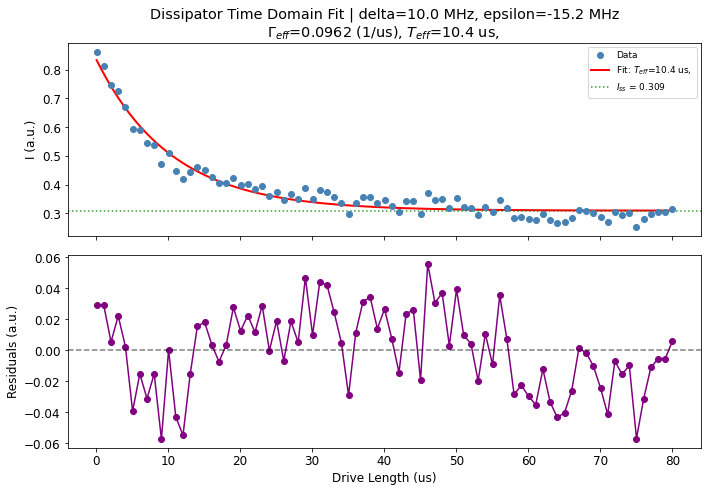

In [96]:

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axs[0].plot(drive_length_list, i_data_diss, 'o',
            color='steelblue', label='Data', zorder=3)
axs[0].plot(t_fine, I_fit, '-', color='red', linewidth=2,
            label=f'Fit: $T_{{eff}}$={T_eff:.1f} us, '
                  )
axs[0].axhline(I_ss_fit, color='green', linestyle=':',
               alpha=0.8, label=f'$I_{{ss}}$ = {I_ss_fit:.3f}')
axs[0].set_ylabel("I (a.u.)")
axs[0].legend(fontsize=9)
axs[0].set_title(
    f"Dissipator Time Domain Fit | "
    f"delta={expt_cfg['delta']} MHz, "
    f"epsilon={expt_cfg['epsilon']} MHz\n"
    f"$\\Gamma_{{eff}}$={Gamma_eff_fit:.4f} (1/us), "
    #f"$\\Gamma_{{diss}}$={Gamma_diss:.4f} (1/us), "
    f"$T_{{eff}}$={T_eff:.1f} us, "
    #f"$P_e^{{ss}}$={P_e_ss:.2f}"
)

# Residuals
residuals = i_data_diss - dissipation_model(drive_length_list, *popt)
axs[1].plot(drive_length_list, residuals, 'o-', color='purple')
axs[1].axhline(0, color='k', linestyle='--', alpha=0.5)
axs[1].set_ylabel("Residuals (a.u.)")
axs[1].set_xlabel("Drive Length (us)")

plt.tight_layout()
plt.show()